# DEAP Feature Extraction: Physiological & Audio

This notebook demonstrates feature extraction for both physiological (EEG/physio) and audio (MIDI) data from the DEAP dataset, preparing for multimodal fusion.

In [1]:
import os
import sys
# Add the parent directory to sys.path so 'src' can be found
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.acquisition import load_deap

# For MIDI/audio processing
import pretty_midi

sns.set(style='whitegrid')

In [2]:
# Path to DEAP physiological data
PHYSIO_DATA_DIR = '../db/deap-dataset/data_preprocessed_python'
data = load_deap(PHYSIO_DATA_DIR)
physio_array= data['physio']
labels_array = data['labels']
print(f"Loaded {len(physio_array)} physio trials. Labels shape: {labels_array.shape}")

Loaded 1280 physio trials. Labels shape: (1280, 4)


In [3]:
import numpy as np
import pandas as pd

def extract_temporal_stats(signal, n_segments=20):
    segments = np.array_split(signal, n_segments)
    feats = []

    for seg in segments:
        feats.extend([
            np.mean(seg),
            np.std(seg),
        ])

    return np.array(feats)


def extract_physio_features(physio_array, n_segments=20):
    """
    physio_array: (n_trials, n_channels, n_samples)
    """
    all_features = []

    for trial in physio_array:
        trial_feats = []

        for ch in range(trial.shape[0]):
            ch_signal = trial[ch]
            ch_feats = extract_temporal_stats(ch_signal, n_segments)
            trial_feats.extend(ch_feats)

        all_features.append(trial_feats)

    return np.array(all_features)


# Apply new extraction
physio_features = extract_physio_features(physio_array, n_segments=20)

# Convert to DataFrame
physio_features_df = pd.DataFrame(physio_features)
physio_features_df.head()

,0,1,2,3,4,5,6,7,8,9,...,310,311,312,313,314,315,316,317,318,319
0,9.199039,0.0,-18.864711,0.0,13.109188,0.0,8.973942,0.0,-637.872315,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-22.607217,0.0,-1.271482,0.0,20.931358,0.0,48.697501,0.0,-1714.953788,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,-3.141840,0.0,-3.332188,0.0,8.261948,0.0,-22.157104,0.0,623.350301,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,21.056032,0.0,10.835266,0.0,23.616656,0.0,-4.819327,0.0,-338.973384,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,12.782854,0.0,11.375874,0.0,-13.040015,0.0,21.742717,0.0,-400.593587,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


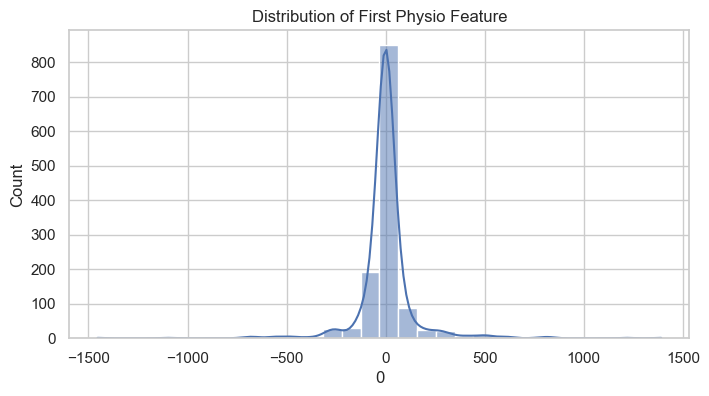

In [4]:
# Summary statistics for extracted physio features
physio_features_df.describe()

# Visualize distribution of a sample feature
plt.figure(figsize=(8,4))
sns.histplot(physio_features_df.iloc[:,0], bins=30, kde=True)
plt.title('Distribution of First Physio Feature')
plt.show()

In [5]:
MIDI_DIR = '../db/deap-dataset/audio_stimuli_MIDI'
midi_files = sorted([f for f in os.listdir(MIDI_DIR) if f.endswith('.mid')])
print(f"Found {len(midi_files)} MIDI files. Example: {midi_files[:3]}")

Found 40 MIDI files. Example: ['exp_id_1.mid', 'exp_id_10.mid', 'exp_id_11.mid']


In [6]:
def midi_temporal_features(midi_path, n_segments=10):
    midi = pretty_midi.PrettyMIDI(midi_path)
    duration = midi.get_end_time()

    if duration == 0:
        return np.zeros(n_segments * 2)

    segment_times = np.linspace(0, duration, n_segments + 1)
    feats = []

    for i in range(n_segments):
        start, end = segment_times[i], segment_times[i+1]
        notes = []

        for instrument in midi.instruments:
            for note in instrument.notes:
                if start <= note.start < end:
                    notes.append(note.pitch)

        if len(notes) == 0:
            feats.extend([0, 0])
        else:
            feats.extend([
                np.mean(notes),
                len(notes)
            ])

    return np.array(feats)

In [7]:
import os
import pandas as pd

audio_features = []

for fname in midi_files:
    feats = midi_temporal_features(
        os.path.join(MIDI_DIR, fname),
        n_segments=10
    )
    audio_features.append(feats)

# Create DataFrame
audio_features_df = pd.DataFrame(audio_features)

# Assign meaningful column names
n_segments = 10
col_names = []

for i in range(n_segments):
    col_names.append(f"seg_{i+1}_mean")
    col_names.append(f"seg_{i+1}_std")

audio_features_df.columns = col_names

# Preview
audio_features_df.head()

,seg_1_mean,seg_1_std,seg_2_mean,seg_2_std,seg_3_mean,seg_3_std,seg_4_mean,seg_4_std,seg_5_mean,seg_5_std,seg_6_mean,seg_6_std,seg_7_mean,seg_7_std,seg_8_mean,seg_8_std,seg_9_mean,seg_9_std,seg_10_mean,seg_10_std
0,59.971014,69.0,56.714286,42.0,56.349206,63.0,49.367347,49.0,51.120000,50.0,53.342105,38.0,57.446154,65.0,58.347222,72.0,57.985294,68.0,45.428571,14.0
1,44.436620,71.0,43.465517,58.0,45.187500,64.0,38.347826,23.0,41.048780,41.0,41.857143,42.0,41.511628,43.0,39.466667,15.0,43.590909,44.0,42.032258,31.0
2,52.815789,38.0,51.304348,23.0,50.650000,40.0,47.352941,34.0,47.875000,32.0,48.636364,33.0,45.740741,27.0,46.615385,26.0,49.709677,31.0,42.700000,30.0
3,50.558824,34.0,54.758621,58.0,53.114754,61.0,54.024390,41.0,49.000000,38.0,55.229167,48.0,55.234043,47.0,54.021277,47.0,54.739130,46.0,54.357143,14.0
4,60.650000,40.0,59.500000,40.0,57.848485,33.0,57.642857,42.0,54.333333,33.0,57.545455,44.0,55.578947,38.0,54.368421,38.0,55.418605,43.0,56.902439,41.0


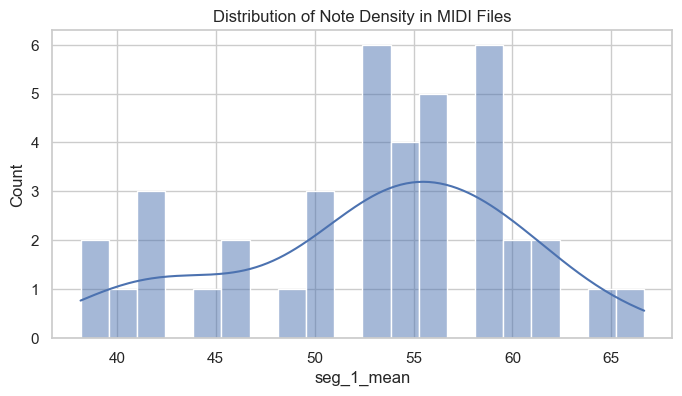

In [8]:
# Summary statistics for extracted audio features
audio_features_df.describe()

# Visualize distribution of a sample audio feature
plt.figure(figsize=(8,4))
sns.histplot(audio_features_df['seg_1_mean'], bins=20, kde=True)
plt.title('Distribution of Note Density in MIDI Files')
plt.show()

In [9]:
physio_features_df.to_csv('../db/physio_features.csv', index=False)
audio_features_df.to_csv('../db/audio_features.csv', index=False)
print('Feature CSVs saved: ../db/physio_features.csv, ../db/audio_features.csv')

Feature CSVs saved: ../db/physio_features.csv, ../db/audio_features.csv
